# 06 — Topic Trend Monitoring

> **Which topics are accelerating and may require early intervention?**

| | |
|---|---|
| **Audience** | Operations leads, product owners |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~10 s on the bundled sample |
| **Reproduces from** | `reports/sample/complaint_scores.csv + reports/sample/topic_terms.csv` |

## Business question

Which discovered complaint topics are accelerating month-over-month, and which are mature enough to warrant remediation today?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/06/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/06/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("06")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,06


## 1. Load pipeline outputs

In [2]:
scores, topic_terms = load_pipeline_outputs(ctx)
scores = scores.dropna(subset=["date_received", "topic_id"]).copy()
scores["topic_id"] = scores["topic_id"].astype(int)
scores["month"] = scores["date_received"].dt.to_period("M").astype(str)
labels = topic_labels(topic_terms, top_n=5)
observed_months = scores["month"].nunique()
print(f"Scored complaints: {len(scores):,} across {observed_months} month(s).")

Scored complaints: 1,000 across 1 month(s).


C:\Users\diogo\AppData\Local\Temp\ipykernel_48368\2779187284.py:4: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  scores["month"] = scores["date_received"].dt.to_period("M").astype(str)


## 2. Monthly topic share table

In [3]:
monthly_counts = (
    scores.groupby(["month", "topic_id"], as_index=False).size().rename(columns={"size": "complaints"})
)
monthly_totals = monthly_counts.groupby("month")["complaints"].sum().rename("month_total")
monthly_topic = monthly_counts.merge(monthly_totals, on="month", how="left")
monthly_topic["topic_share_pct"] = (
    monthly_topic["complaints"] / monthly_topic["month_total"] * 100
).round(2)
monthly_topic = monthly_topic.merge(labels, on="topic_id", how="left")
monthly_topic.head(15)

,month,topic_id,complaints,month_total,topic_share_pct,topic_label
0,2024-06,0,329,1000,32.90,"redacted, redacted redacted, money, account, b..."
1,2024-06,1,63,1000,6.30,"consumer, 15, section, states, 1681"
2,2024-06,2,39,1000,3.90,"accounts, fcra 605b, significance eliminating,..."
3,2024-06,3,66,1000,6.60,"payment, late, payments, creditor, late payment"
4,2024-06,4,410,1000,41.00,"credit, report, credit report, information, ac..."
5,2024-06,5,20,1000,2.00,"payments, perplexing discover, perplexing, upd..."
6,2024-06,6,21,1000,2.10,"letters, party involved, really sure, falsely ..."
7,2024-06,7,52,1000,5.20,"consumer reports, consent, consumer, reports, ..."


## 3. Trend deltas and emerging-topic flags

In [4]:
monthly_topic = monthly_topic.sort_values(["topic_id", "month"]).copy()
monthly_topic["share_delta_pp"] = (
    monthly_topic.groupby("topic_id")["topic_share_pct"].diff()
)

def _previous_share(series: pd.Series) -> float | None:
    if len(series) < 2:
        return None
    return float(series.iloc[-2])

trend_summary = (
    monthly_topic.groupby(["topic_id", "topic_label"], as_index=False)
    .agg(
        avg_share_pct=("topic_share_pct", "mean"),
        latest_share_pct=("topic_share_pct", "last"),
        previous_share_pct=("topic_share_pct", _previous_share),
        latest_delta_pp=("share_delta_pp", "last"),
        observations=("month", "nunique"),
    )
    .sort_values("latest_delta_pp", ascending=False, na_position="last")
)
trend_summary[["avg_share_pct", "latest_share_pct", "previous_share_pct", "latest_delta_pp"]] = (
    trend_summary[["avg_share_pct", "latest_share_pct", "previous_share_pct", "latest_delta_pp"]].round(2)
)
trend_summary["emerging_flag"] = (
    trend_summary["latest_delta_pp"].fillna(0) >= 2.0
) & (trend_summary["latest_share_pct"] >= 5.0) & (trend_summary["observations"] >= 2)
trend_summary

,topic_id,topic_label,avg_share_pct,latest_share_pct,previous_share_pct,latest_delta_pp,observations,emerging_flag
0,0,"redacted, redacted redacted, money, account, b...",32.90,32.90,None,NaN,1,False
1,1,"consumer, 15, section, states, 1681",6.30,6.30,None,NaN,1,False
2,2,"accounts, fcra 605b, significance eliminating,...",3.90,3.90,None,NaN,1,False
3,3,"payment, late, payments, creditor, late payment",6.60,6.60,None,NaN,1,False
4,4,"credit, report, credit report, information, ac...",41.00,41.00,None,NaN,1,False
5,5,"payments, perplexing discover, perplexing, upd...",2.00,2.00,None,NaN,1,False
6,6,"letters, party involved, really sure, falsely ...",2.10,2.10,None,NaN,1,False
7,7,"consumer reports, consent, consumer, reports, ...",5.20,5.20,None,NaN,1,False


## 4. Top topics over time

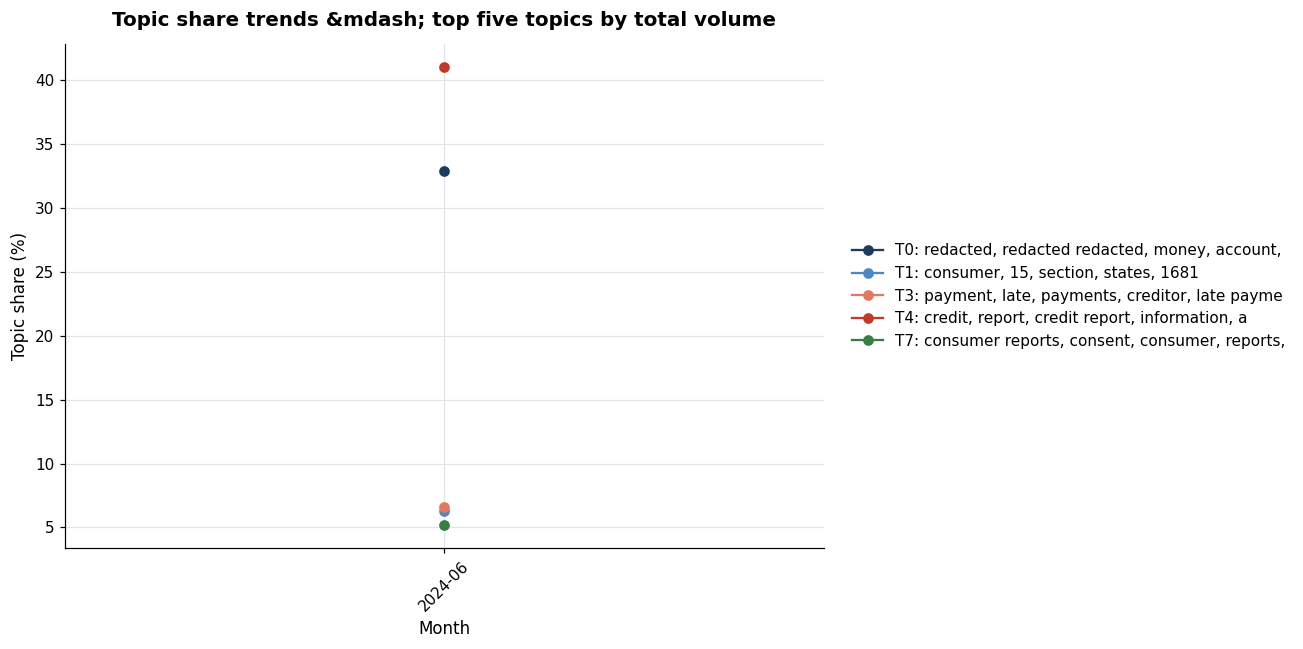

In [5]:
top_topic_ids = (
    monthly_topic.groupby("topic_id")["complaints"].sum().sort_values(ascending=False).head(5).index.tolist()
)
plot_data = monthly_topic[monthly_topic["topic_id"].isin(top_topic_ids)].copy()
fig, ax = plt.subplots(figsize=(12, 6))
palette = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"], PALETTE["warning"], PALETTE["positive"]]
for (topic_id, group), color in zip(plot_data.groupby("topic_id"), palette):
    label_text = f"T{int(topic_id)}: {group['topic_label'].iloc[0][:45]}"
    ax.plot(group["month"], group["topic_share_pct"], marker="o", color=color, label=label_text)
ax.set_title("Topic share trends &mdash; top five topics by total volume")
ax.set_xlabel("Month")
ax.set_ylabel("Topic share (%)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.tight_layout()
save_figure(ctx, fig, "topic_share_trends")
plt.show()

## 5. Insights

In [6]:
emerging = trend_summary[trend_summary["emerging_flag"]]
if observed_months < 2:
    text = (
        "- Only one month of data is present in the sample, so trend deltas cannot be computed. "
        "Re-run the pipeline against a multi-month fetch to enable this notebook."
    )
elif emerging.empty:
    text = (
        "- **No emerging topics** under the current rule "
        "(delta >= 2 percentage points, latest share >= 5%, at least 2 months observed). "
        "The complaint mix is stable on the bundled sample."
    )
else:
    rows = []
    for _, row in emerging.head(3).iterrows():
        rows.append(
            f"- **Topic {int(row['topic_id'])}** ({row['topic_label']}): "
            f"now {row['latest_share_pct']:.1f}% of complaints (+{row['latest_delta_pp']:.1f}pp WoM)."
        )
    text = "\n".join(rows)
display(Markdown(text))

- Only one month of data is present in the sample, so trend deltas cannot be computed. Re-run the pipeline against a multi-month fetch to enable this notebook.

## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/06/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [7]:
save_table(ctx, monthly_topic, "monthly_topic_share")
save_table(ctx, trend_summary.reset_index(drop=True), "topic_trend_summary")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/06/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/06/monthly_topic_share.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/06/topic_share_trends.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/06/topic_trend_summary.csv')]